# ETS Deep Learning — Pengenalan Angka Tulisan Tangan (MNIST) dengan Deep Feedforward Network (MLP)

**Framework:** TensorFlow / Keras  |  **Platform:** Google Colab

**Dua konfigurasi model**
1. **Model dasar**: MLP tanpa Dropout dan tanpa Early Stopping.
2. **Model regularisasi**: MLP yang sama + Dropout + Early Stopping (`val_loss`, `restore_best_weights=True`).

**Alur notebook (jalankan berurutan dari atas: Runtime → Run all)**

| Bagian | Isi |
|---|---|
| 1 | Konfigurasi, seed, dan pencatatan seluruh pengaturan |
| 2 | Memuat data MNIST |
| 3 | Split berstrata 80/20, normalisasi 0–1, flatten 784 fitur |
| 4 | Contoh data beserta label |
| 5 | Arsitektur jaringan (kedua model, bobot awal identik) |
| 6 | Pelatihan (atau memuat model tersimpan saat demo) |
| 7 | Grafik akurasi dan loss |
| 8 | Memilih model akhir **berdasarkan validasi** |
| 9 | Akurasi pada data pengujian (hanya sekali, model terpilih saja) |
| 10 | Fitur prediksi gambar dari data pengujian |
| 11 | Mengemas hasil untuk dikumpulkan |

> **Saat demo:** ubah `RETRAIN = False` di Bagian 1 lalu *Run all*. Model dan riwayat pelatihan akan dimuat dari folder `artifacts/` tanpa melatih ulang.

## 1. Konfigurasi, seed, dan pencatatan pengaturan

In [ ]:
import os, json, random, time, shutil, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| Python:", platform.python_version())
print("GPU terdeteksi:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.12.4 | Python: 3.10.11


GPU terdeteksi: []


In [ ]:
# ====== SAKLAR UTAMA ======
RETRAIN = False      # True  = latih ulang kedua model (dan simpan)
                    # False = muat model & riwayat dari folder artifacts/ (untuk demo)

# ====== RANDOM SEED (reprodusibilitas) ======
SEED = 42
keras.utils.set_random_seed(SEED)          # mengatur seed Python, NumPy, dan TensorFlow sekaligus
try:
    tf.config.experimental.enable_op_determinism()
except Exception as e:
    print("Mode deterministik tidak aktif:", e)

# ====== SELURUH PENGATURAN (SAMA untuk kedua konfigurasi, kecuali Dropout & Early Stopping) ======
CONFIG = {
    "seed": SEED,
    "data_source": "keras",                 # "keras" (keras.datasets.mnist) atau "csv"
    "csv_train": "data/mnist_train.csv",    # dipakai jika data_source == "csv"
    "csv_test":  "data/mnist_test.csv",
    "val_size": 0.2,                        # 80% latih / 20% validasi, berstrata
    "input_dim": 784,
    "hidden_units": [256, 128],             # 2 hidden layer, aktivasi ReLU
    "num_classes": 10,                      # output Softmax
    "dropout_rate": 0.3,                    # hanya model regularisasi
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "batch_size": 128,
    "max_epochs": 30,
    "loss": "sparse_categorical_crossentropy",   # label berupa bilangan bulat 0-9
    "es_monitor": "val_loss",               # hanya model regularisasi
    "es_patience": 5,
    "es_restore_best_weights": True,
}
ARTIFACT_DIR = Path("artifacts"); ARTIFACT_DIR.mkdir(exist_ok=True)

env_info = {"tensorflow": tf.__version__, "keras": keras.__version__,
            "python": platform.python_version(), "numpy": np.__version__}
with open(ARTIFACT_DIR / "config.json", "w") as f:
    json.dump({"config": CONFIG, "environment": env_info}, f, indent=2)
print(json.dumps(CONFIG, indent=2))

{
  "seed": 42,
  "data_source": "keras",
  "csv_train": "data/mnist_train.csv",
  "csv_test": "data/mnist_test.csv",
  "val_size": 0.2,
  "input_dim": 784,
  "hidden_units": [
    256,
    128
  ],
  "num_classes": 10,
  "dropout_rate": 0.3,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "batch_size": 128,
  "max_epochs": 30,
  "loss": "sparse_categorical_crossentropy",
  "es_monitor": "val_loss",
  "es_patience": 5,
  "es_restore_best_weights": true
}


## 2. Memuat data MNIST
Sumber dipilih lewat `CONFIG["data_source"]`. **Pilih satu sumber saja** (jangan digabung).
- `"keras"`: `keras.datasets.mnist.load_data()` (paling mudah di Colab).
- `"csv"`: `mnist_train.csv` dan `mnist_test.csv`; fungsi di bawah **memeriksa header** agar baris data tidak terbuang atau terbaca sebagai header.

In [ ]:
def read_mnist_csv(path):
    """Baca CSV MNIST (kolom 0 = label, 784 kolom sisanya = piksel). Deteksi header otomatis."""
    first = pd.read_csv(path, header=None, nrows=1)
    has_header = pd.to_numeric(first.iloc[0], errors="coerce").isna().any()   # baris pertama berisi teks -> header
    df = pd.read_csv(path, header=0 if has_header else None)
    print(f"{path}: header terdeteksi = {has_header} | shape = {df.shape}")
    arr = df.to_numpy()
    return arr[:, 1:].astype("uint8"), arr[:, 0].astype("int64")

if CONFIG["data_source"] == "keras":
    (x_tr, y_full), (x_te, y_test) = keras.datasets.mnist.load_data()
    X_full = x_tr.reshape(len(x_tr), -1)          # (60000, 28, 28) -> (60000, 784)
    X_test_raw = x_te.reshape(len(x_te), -1)      # (10000, 28, 28) -> (10000, 784)
    y_full = y_full.astype("int64"); y_test = y_test.astype("int64")
else:
    X_full, y_full = read_mnist_csv(CONFIG["csv_train"])
    X_test_raw, y_test = read_mnist_csv(CONFIG["csv_test"])

# Pemeriksaan validitas data
assert X_full.shape == (60000, 784) and X_test_raw.shape == (10000, 784), "Jumlah data tidak sesuai"
assert set(np.unique(y_full)) == set(range(10)) and set(np.unique(y_test)) == set(range(10)), "Label harus 0-9"
assert X_full.min() == 0 and X_full.max() == 255, "Nilai piksel mentah harus 0-255"
print("Data latih penuh:", X_full.shape, "| Data uji:", X_test_raw.shape)

Data latih penuh:

 (60000, 784) | Data uji: (10000, 784)


## 3. Pembagian data, normalisasi, dan flatten
- Split **berstrata** berdasarkan label: 80% latih, 20% validasi (dari 60.000 data latih).
- **Normalisasi**: piksel dibagi 255 sehingga rentang 0–1.
- Setiap gambar sudah berupa **vektor 784 fitur** (28 × 28 diratakan).
- Data uji (10.000) disimpan khusus untuk pengujian akhir.

In [ ]:
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_full, y_full, test_size=CONFIG["val_size"], stratify=y_full, random_state=SEED)

def normalize(a):
    return a.astype("float32") / 255.0            # 0..255 -> 0..1

X_train, X_val, X_test = normalize(X_train_raw), normalize(X_val_raw), normalize(X_test_raw)

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print(f"Rentang piksel setelah normalisasi: min={X_train.min():.1f}, max={X_train.max():.1f}")
print("\nJumlah sampel per kelas (membuktikan split berstrata):")
display(pd.DataFrame({"latih": np.bincount(y_train), "validasi": np.bincount(y_val), "uji": np.bincount(y_test)}).T)

X_train: (48000, 784) | X_val: (12000, 784) | X_test: (10000, 784)
Rentang piksel setelah normalisasi: min=0.0, max=1.0

Jumlah sampel per kelas (membuktikan split berstrata):


,0,1,2,3,4,5,6,7,8,9
latih,4738,5394,4766,4905,4674,4337,4734,5012,4681,4759
validasi,1185,1348,1192,1226,1168,1084,1184,1253,1170,1190
uji,980,1135,1032,1010,982,892,958,1028,974,1009


## 4. Contoh data beserta labelnya

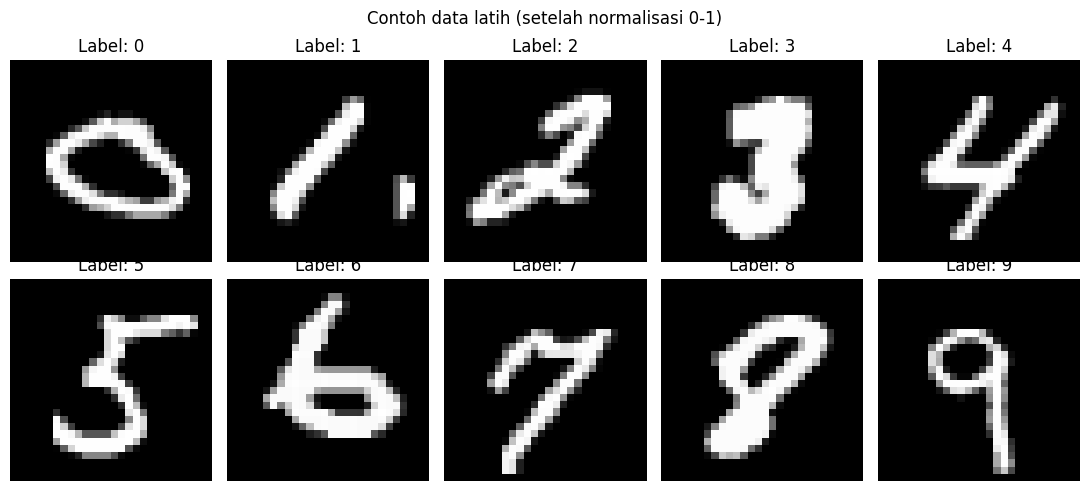

Satu contoh: bentuk vektor = (784,) | label = 1


In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for digit, ax in enumerate(axes.ravel()):
    i = np.where(y_train == digit)[0][0]                 # contoh pertama dari tiap kelas
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")   # vektor 784 -> gambar 28x28 (hanya untuk tampilan)
    ax.set_title(f"Label: {y_train[i]}"); ax.axis("off")
plt.suptitle("Contoh data latih (setelah normalisasi 0-1)"); plt.tight_layout(); plt.show()

print("Satu contoh: bentuk vektor =", X_train[0].shape, "| label =", y_train[0])

## 5. Arsitektur jaringan
```
Input 784 → Dense 256 (ReLU) [→ Dropout] → Dense 128 (ReLU) [→ Dropout] → Dense 10 (Softmax)
```
Kedua model **identik** (jumlah neuron, optimizer, learning rate, batch size, max epoch). Perbedaannya hanya Dropout + Early Stopping.
**Bobot awal dijamin sama**: model regularisasi menyalin bobot awal model dasar, lalu dibuktikan dengan `assert`.

In [ ]:
def build_mlp(dropout_rate=0.0, name="mlp"):
    inputs = keras.Input(shape=(CONFIG["input_dim"],), name="input_784")
    x = inputs
    for i, units in enumerate(CONFIG["hidden_units"], start=1):
        x = layers.Dense(units, activation="relu",
                         kernel_initializer=keras.initializers.GlorotUniform(seed=SEED + i),
                         name=f"hidden_{i}_relu")(x)
        if dropout_rate > 0:
            x = layers.Dropout(dropout_rate, seed=SEED + 100 + i, name=f"dropout_{i}")(x)
    outputs = layers.Dense(CONFIG["num_classes"], activation="softmax",
                           kernel_initializer=keras.initializers.GlorotUniform(seed=SEED + 99),
                           name="output_softmax")(x)
    model = keras.Model(inputs, outputs, name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=CONFIG["learning_rate"]),
                  loss=CONFIG["loss"],               # label integer -> sparse_categorical_crossentropy
                  metrics=["accuracy"])
    return model

model_base = build_mlp(dropout_rate=0.0, name="mlp_dasar")
model_reg  = build_mlp(dropout_rate=CONFIG["dropout_rate"], name="mlp_dropout_earlystopping")

# Samakan bobot awal kedua model, lalu buktikan
model_reg.set_weights(model_base.get_weights())
assert all(np.array_equal(a, b) for a, b in zip(model_base.get_weights(), model_reg.get_weights())), "Bobot awal berbeda!"
print("Bobot awal kedua model IDENTIK.\n")

model_base.summary()
model_reg.summary()

Bobot awal kedua model IDENTIK.



Model: "mlp_dasar"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_784 (InputLayer)          │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1_relu (Dense)           │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2_relu (Dense)           │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

...

Model: "mlp_dropout_earlystopping"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_784 (InputLayer)          │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1_relu (Dense)           │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2_relu (Dense)           │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Pelatihan
- **Model dasar**: tanpa callback.
- **Model regularisasi**: `EarlyStopping(monitor="val_loss", restore_best_weights=True)`.
- Seed diatur ulang sebelum tiap pelatihan, sehingga urutan pengacakan batch sama.
- Model dan riwayat disimpan di `artifacts/`. Jika `RETRAIN = False`, seluruhnya dimuat dari sana.

In [ ]:
paths = {
    "model_base": ARTIFACT_DIR / "model_baseline.keras",
    "model_reg":  ARTIFACT_DIR / "model_dropout_earlystopping.keras",
    "hist_base":  ARTIFACT_DIR / "history_baseline.json",
    "hist_reg":   ARTIFACT_DIR / "history_dropout_earlystopping.json",
}

def train_model(model, callbacks, tag):
    keras.utils.set_random_seed(SEED)
    t0 = time.time()
    h = model.fit(X_train, y_train,
                  validation_data=(X_val, y_val),
                  epochs=CONFIG["max_epochs"], batch_size=CONFIG["batch_size"],
                  shuffle=True, callbacks=callbacks, verbose=2)
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    hist["_meta"] = {"model": tag, "epochs_run": len(h.history["loss"]),
                     "train_seconds": round(time.time() - t0, 1)}
    return hist

if RETRAIN or not all(p.exists() for p in paths.values()):
    print(">>> MELATIH MODEL DASAR (tanpa Dropout, tanpa Early Stopping)")
    hist_base = train_model(model_base, callbacks=[], tag="baseline")
    print("\n>>> MELATIH MODEL REGULARISASI (Dropout + Early Stopping)")
    es = keras.callbacks.EarlyStopping(monitor=CONFIG["es_monitor"], patience=CONFIG["es_patience"],
                                       restore_best_weights=CONFIG["es_restore_best_weights"], verbose=1)
    hist_reg = train_model(model_reg, callbacks=[es], tag="dropout_earlystopping")

    model_base.save(paths["model_base"]); model_reg.save(paths["model_reg"])
    json.dump(hist_base, open(paths["hist_base"], "w"), indent=2)
    json.dump(hist_reg,  open(paths["hist_reg"],  "w"), indent=2)
    print("\nModel dan riwayat pelatihan tersimpan di", ARTIFACT_DIR.resolve())
else:
    print(">>> MODE DEMO: memuat model dan riwayat dari artifacts/ (tanpa melatih ulang)")
    model_base = keras.models.load_model(paths["model_base"])
    model_reg  = keras.models.load_model(paths["model_reg"])
    hist_base  = json.load(open(paths["hist_base"]))
    hist_reg   = json.load(open(paths["hist_reg"]))

for name, h in [("Dasar", hist_base), ("Regularisasi", hist_reg)]:
    best_ep = int(np.argmin(h["val_loss"])) + 1
    print(f"{name}: epoch dijalankan = {h['_meta']['epochs_run']} dari maks {CONFIG['max_epochs']} | epoch val_loss terbaik = {best_ep}")

>>> MODE DEMO: memuat model dan riwayat dari artifacts/ (tanpa melatih ulang)


Dasar: epoch dijalankan = 30 dari maks 30 | epoch val_loss terbaik = 6
Regularisasi: epoch dijalankan = 11 dari maks 30 | epoch val_loss terbaik = 6


## 7. Grafik akurasi dan loss (pelatihan vs validasi)

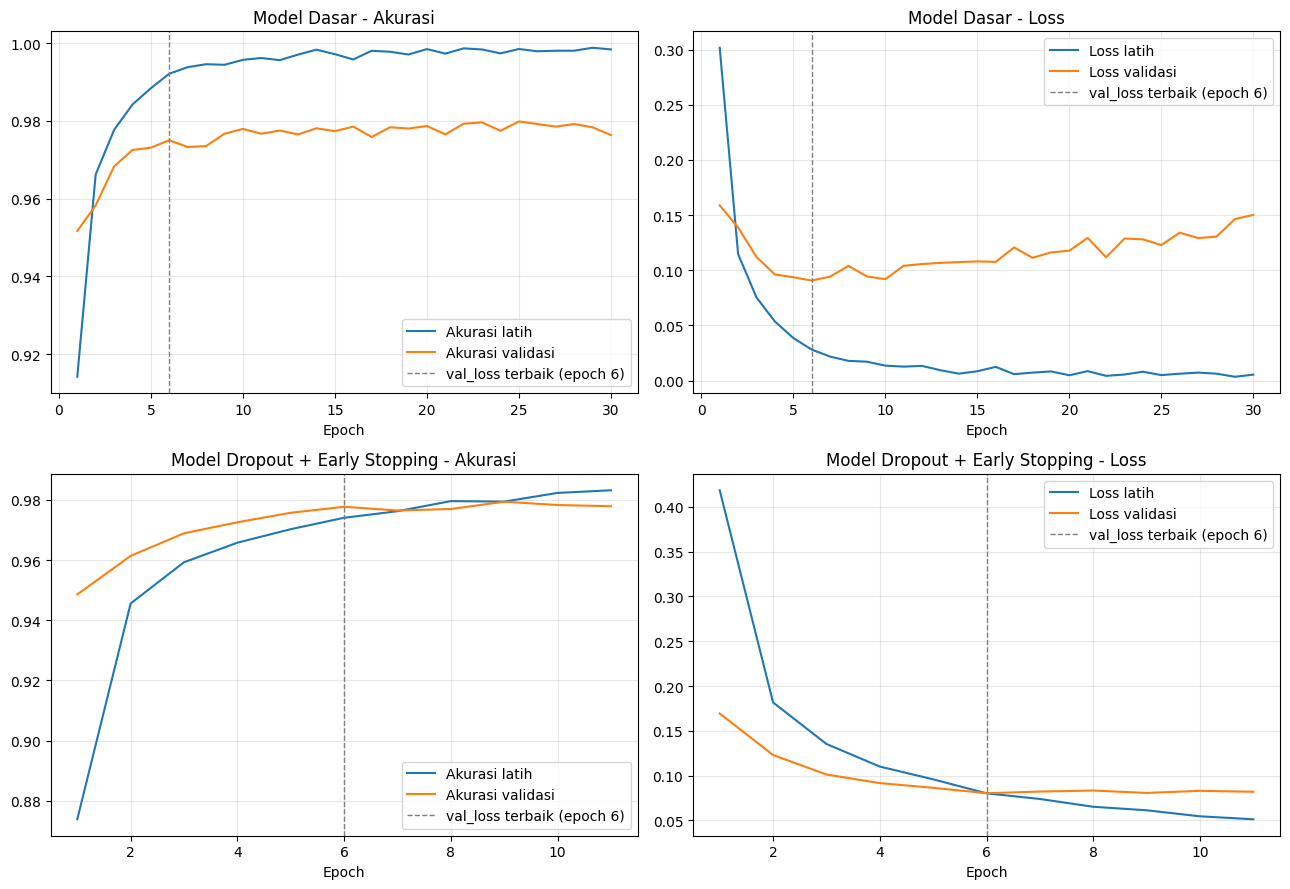

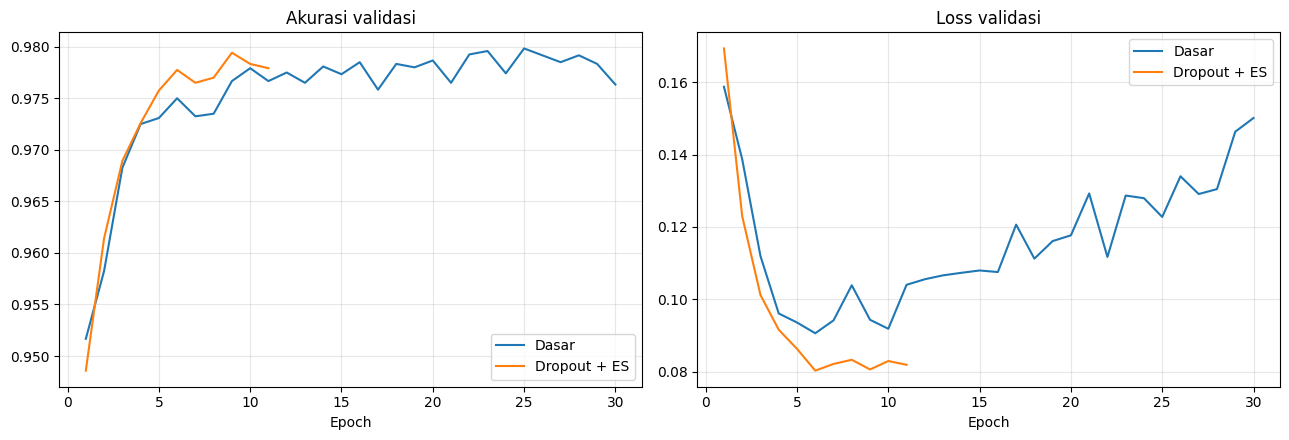

In [ ]:
def plot_pair(h, title, ax_acc, ax_loss):
    ep = np.arange(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"])) + 1
    ax_acc.plot(ep, h["accuracy"], label="Akurasi latih"); ax_acc.plot(ep, h["val_accuracy"], label="Akurasi validasi")
    ax_loss.plot(ep, h["loss"], label="Loss latih");       ax_loss.plot(ep, h["val_loss"], label="Loss validasi")
    for ax in (ax_acc, ax_loss):
        ax.axvline(best, ls="--", c="gray", lw=1, label=f"val_loss terbaik (epoch {best})")
        ax.set_xlabel("Epoch"); ax.grid(alpha=.3); ax.legend()
    ax_acc.set_title(f"{title} - Akurasi"); ax_loss.set_title(f"{title} - Loss")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_pair(hist_base, "Model Dasar", axes[0, 0], axes[0, 1])
plot_pair(hist_reg, "Model Dropout + Early Stopping", axes[1, 0], axes[1, 1])
plt.tight_layout(); plt.savefig(ARTIFACT_DIR / "grafik_pelatihan.png", dpi=130); plt.show()

# Perbandingan langsung data validasi kedua model
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for h, lab in [(hist_base, "Dasar"), (hist_reg, "Dropout + ES")]:
    ep = np.arange(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["val_accuracy"], label=lab); axes[1].plot(ep, h["val_loss"], label=lab)
axes[0].set_title("Akurasi validasi"); axes[1].set_title("Loss validasi")
for ax in axes: ax.set_xlabel("Epoch"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(ARTIFACT_DIR / "grafik_perbandingan_validasi.png", dpi=130); plt.show()

In [ ]:
# Evaluasi bobot AKHIR kedua model pada data latih dan validasi (BUKAN data uji)
rows, val_results = [], {}
for name, model, h in [("Dasar (tanpa Dropout/ES)", model_base, hist_base),
                       ("Regularisasi (Dropout + ES)", model_reg, hist_reg)]:
    tr_loss, tr_acc = model.evaluate(X_train, y_train, verbose=0)
    va_loss, va_acc = model.evaluate(X_val, y_val, verbose=0)
    val_results[name] = {"val_loss": va_loss, "val_accuracy": va_acc}
    rows.append({"Model": name, "Epoch dijalankan": h["_meta"]["epochs_run"],
                 "Akurasi latih": tr_acc, "Akurasi validasi": va_acc,
                 "Selisih (latih - val)": tr_acc - va_acc,
                 "Loss latih": tr_loss, "Loss validasi": va_loss})
summary_df = pd.DataFrame(rows).set_index("Model")
display(summary_df.style.format({c: "{:.4f}" for c in summary_df.columns if c != "Epoch dijalankan"}))
summary_df.to_csv(ARTIFACT_DIR / "ringkasan_latih_validasi.csv")

,Epoch dijalankan,Akurasi latih,Akurasi validasi,Selisih (latih - val),Loss latih,Loss validasi
Model,,,,,,
Dasar (tanpa Dropout/ES),30,0.9969,0.9763,0.0205,0.0106,0.1501
Regularisasi (Dropout + ES),11,0.9889,0.9778,0.0111,0.0367,0.0803


## 8. Memilih model akhir (berdasarkan VALIDASI saja)
**Kriteria:** loss validasi terendah; jika sama persis, dipilih akurasi validasi tertinggi. Data pengujian **tidak** dipakai di bagian ini.

In [ ]:
models_by_name = {"Dasar (tanpa Dropout/ES)": model_base, "Regularisasi (Dropout + ES)": model_reg}
final_name = min(val_results, key=lambda n: (val_results[n]["val_loss"], -val_results[n]["val_accuracy"]))
final_model = models_by_name[final_name]
print("Hasil validasi:")
for n, r in val_results.items():
    print(f"  {n:30s} val_loss = {r['val_loss']:.4f} | val_acc = {r['val_accuracy']:.4f}")
print(f"\n==> MODEL AKHIR TERPILIH: {final_name}")

final_model.save(ARTIFACT_DIR / "model_final.keras")
json.dump({"selected_model": final_name, "criterion": "lowest validation loss (tie: highest validation accuracy)",
           "validation_results": val_results}, open(ARTIFACT_DIR / "pemilihan_model.json", "w"), indent=2)

Hasil validasi:
  Dasar (tanpa Dropout/ES)       val_loss = 0.1501 | val_acc = 0.9763
  Regularisasi (Dropout + ES)    val_loss = 0.0803 | val_acc = 0.9778

==> MODEL AKHIR TERPILIH: Regularisasi (Dropout + ES)


## 9. Akurasi pada data pengujian
Dihitung **sekali** untuk model terpilih. Hasil ini tidak dipakai untuk mengubah model atau hyperparameter.

AKURASI PENGUJIAN (Regularisasi (Dropout + ES)): 0.9765  (97.65%) | loss = 0.0757



               precision    recall  f1-score   support

           0     0.9837    0.9867    0.9852       980
           1     0.9877    0.9912    0.9894      1135
           2     0.9824    0.9738    0.9781      1032
           3     0.9763    0.9782    0.9773      1010
           4     0.9706    0.9745    0.9726       982
           5     0.9819    0.9709    0.9763       892
           6     0.9688    0.9739    0.9714       958
           7     0.9693    0.9835    0.9763      1028
           8     0.9739    0.9579    0.9658       974
           9     0.9693    0.9713    0.9703      1009

    accuracy                         0.9765     10000
   macro avg     0.9764    0.9762    0.9763     10000
weighted avg     0.9765    0.9765    0.9765     10000



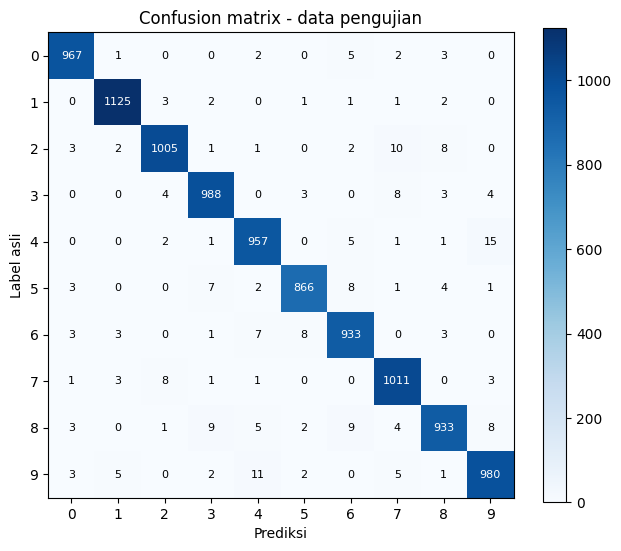

In [ ]:
test_loss, test_acc = final_model.evaluate(X_test, y_test, verbose=0)
print(f"AKURASI PENGUJIAN ({final_name}): {test_acc:.4f}  ({test_acc*100:.2f}%) | loss = {test_loss:.4f}")

y_pred_test = np.argmax(final_model.predict(X_test, verbose=0), axis=1)
print("\n", classification_report(y_test, y_pred_test, digits=4))

cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(6.5, 5.5)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(10)); plt.yticks(range(10)); plt.xlabel("Prediksi"); plt.ylabel("Label asli")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max()/2 else "black")
plt.title("Confusion matrix - data pengujian"); plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "confusion_matrix_test.png", dpi=130); plt.show()

json.dump({"selected_model": final_name, "test_accuracy": float(test_acc), "test_loss": float(test_loss)},
          open(ARTIFACT_DIR / "hasil_pengujian.json", "w"), indent=2)

## 10. Fitur prediksi gambar dari data pengujian
Tersedia tiga cara: (a) `predict_test_image(indeks)`, (b) `predict_many([...])` untuk beberapa gambar sekaligus, (c) widget interaktif.

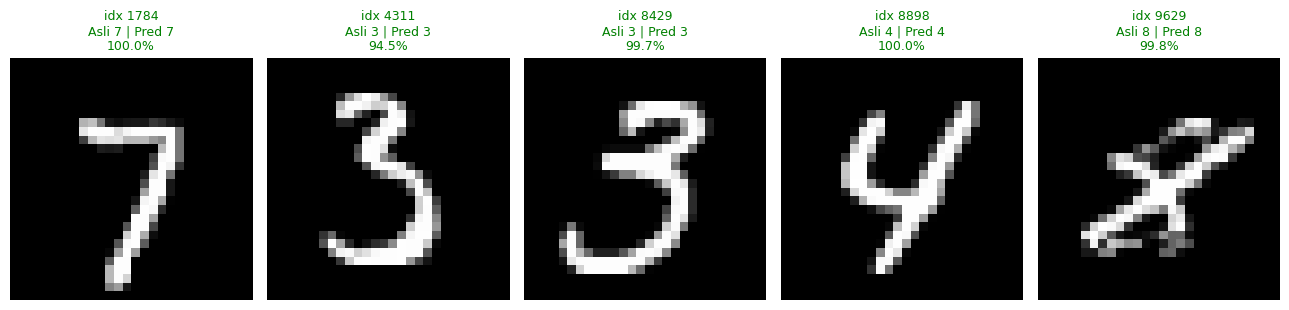

,P(0) %,P(1) %,P(2) %,P(3) %,P(4) %,P(5) %,P(6) %,P(7) %,P(8) %,P(9) %
idx 1784,0.0,0.00,0.00,0.000000,0.00,0.00,0.0,100.0,0.000000,0.00
idx 4311,0.0,0.00,0.00,94.489998,0.00,5.48,0.0,0.0,0.000000,0.02
idx 8429,0.0,0.00,0.00,99.720001,0.00,0.02,0.0,0.0,0.000000,0.27
idx 8898,0.0,0.00,0.00,0.000000,100.00,0.00,0.0,0.0,0.000000,0.00
idx 9629,0.0,0.03,0.06,0.050000,0.06,0.02,0.0,0.0,99.760002,0.01


In [ ]:
def predict_test_image(idx, model=None, show=True):
    """Tampilkan gambar uji ke-idx, angka prediksi, dan probabilitas tiap kelas."""
    model = model or final_model
    idx = int(idx)
    probs = model.predict(X_test[idx:idx + 1], verbose=0)[0]        # output Softmax: 10 probabilitas, jumlah = 1
    pred, true = int(np.argmax(probs)), int(y_test[idx])
    if show:
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2]})
        a1.imshow(X_test[idx].reshape(28, 28), cmap="gray"); a1.axis("off")
        a1.set_title(f"Indeks uji {idx} | Label asli: {true}")
        a2.bar(range(10), probs * 100, color=["tab:green" if i == pred else "lightgray" for i in range(10)])
        a2.set_xticks(range(10)); a2.set_xlabel("Angka"); a2.set_ylabel("Probabilitas (%)"); a2.set_ylim(0, 112)
        for i, p in enumerate(probs):
            a2.text(i, p * 100 + 1.5, f"{p*100:.1f}%", ha="center", fontsize=8)
        a2.set_title(f"Prediksi: {pred} (prob. {probs[pred]*100:.2f}%) - {'BENAR' if pred == true else 'SALAH'}")
        plt.tight_layout(); plt.show()
    return pred, probs

def predict_many(indices, model=None):
    """Prediksi beberapa gambar uji sekaligus (mis. minimal 5 gambar yang dipilih saat demo)."""
    model = model or final_model
    fig, axes = plt.subplots(1, len(indices), figsize=(2.6 * len(indices), 3.2))
    axes = np.atleast_1d(axes); table = {}
    for ax, idx in zip(axes, indices):
        pred, probs = predict_test_image(idx, model, show=False)
        ax.imshow(X_test[idx].reshape(28, 28), cmap="gray"); ax.axis("off")
        ok = pred == y_test[idx]
        ax.set_title(f"idx {idx}\nAsli {y_test[idx]} | Pred {pred}\n{probs[pred]*100:.1f}%", color="green" if ok else "red", fontsize=9)
        table[f"idx {idx}"] = np.round(probs * 100, 2)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame(table, index=[f"P({d}) %" for d in range(10)]).T)

# Contoh: 5 gambar acak dari data uji (ganti daftar indeks sesuai pilihan saat demo)
rng = np.random.default_rng()
predict_many(sorted(rng.choice(len(X_test), 5, replace=False).tolist()))

In [ ]:
# Widget interaktif: pilih indeks gambar uji, lalu klik "Prediksi" (atau "Acak")
import ipywidgets as widgets
from IPython.display import display, clear_output

w_idx  = widgets.BoundedIntText(value=0, min=0, max=len(X_test) - 1, description="Indeks:")
w_pred = widgets.Button(description="Prediksi", button_style="primary")
w_rand = widgets.Button(description="Acak")
w_out  = widgets.Output()

def _run(_=None):
    with w_out:
        clear_output(wait=True); predict_test_image(w_idx.value)
def _random(_=None):
    w_idx.value = int(np.random.randint(0, len(X_test))); _run()

w_pred.on_click(_run); w_rand.on_click(_random)
display(widgets.HBox([w_idx, w_pred, w_rand]), w_out)

Output()

## 11. Mengemas hasil untuk dikumpulkan

In [ ]:
# Mengemas folder artifacts/ (model, riwayat, grafik, konfigurasi) menjadi satu berkas ZIP
zip_path = shutil.make_archive("hasil_pelatihan_artifacts", "zip", ARTIFACT_DIR)
print("Berkas dibuat:", zip_path)
print(sorted(p.name for p in ARTIFACT_DIR.iterdir()))
try:
    from google.colab import files
    files.download(zip_path)           # di Colab: mengunduh ke komputer
except ImportError:
    pass

Berkas dibuat: C:\Users\Administrator\Documents\File Kuliah\DEEP LEARNING\ETS_DeepLearning_Paket\hasil_pelatihan_artifacts.zip
['BACA_SAYA.txt', 'config.json', 'confusion_matrix_test.png', 'grafik_pelatihan.png', 'grafik_perbandingan_validasi.png', 'hasil_pengujian.json', 'history_baseline.json', 'history_dropout_earlystopping.json', 'model_baseline.keras', 'model_dropout_earlystopping.keras', 'model_final.keras', 'pemilihan_model.json', 'ringkasan_latih_validasi.csv']
